YF.download() has changed argument auto_adjust default to True


c:\Users\Natck\AppData\Local\Programs\Python\Python313\Lib\site-packages\yfinance\scrapers\history.py:173: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
[*********************100%***********************]  6 of 6 completed


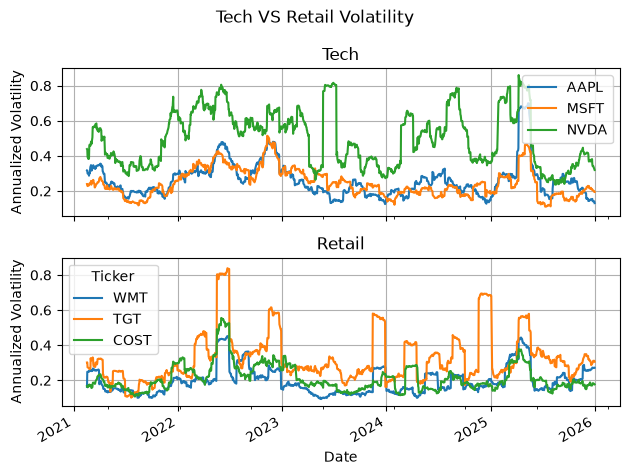

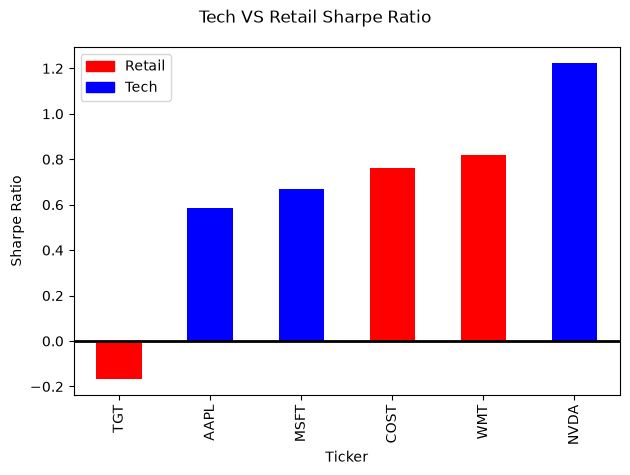

In [ ]:
import pandas as pd         
import yfinance as yf
import numpy as np  
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

data = yf.download(["AAPL", "MSFT", "NVDA", "WMT", "TGT", "COST"], start="2021-01-01", end="2026-01-01")
close_prices = data["Close"]
returns = close_prices.pct_change().dropna()

annual_returns = returns.mean() * 252
annual_volatility = returns.std() * 252 **0.5

# Rolling Volatility = STD * sqr(252)
rolling_volatility = returns.rolling(window=30).std() * 252 **0.5
# print(rolling_volatility)

sharpe = (annual_returns - 0.03)/annual_volatility

# Line graph
figure, axes = plt.subplots(2,1,sharex=True, sharey=True)

rolling_volatility[["AAPL", "MSFT", "NVDA"]].plot(ax=axes[0])
rolling_volatility[["WMT", "TGT", "COST"]].plot(ax=axes[1])

figure.suptitle("Tech VS Retail Volatility")

axes[0].set_title("Tech")
axes[0].set_ylabel("Annualized Volatility")
axes[0].grid(True)
axes[0].legend(loc="upper right")

axes[1].set_title("Retail")
axes[1].set_ylabel("Annualized Volatility")
axes[1].grid(True)

# Bar graph
figure2, ax = plt.subplots()

sharpe.sort_values().plot(kind="bar",ax=ax,color=["orange", "blue", "blue", "orange", "orange", "blue"])
ax.axhline(0, color="black", linewidth=2)
ax.legend(handles=[Patch(color="orange", label="Retail"), Patch(color="blue", label="Tech")])

ax.set_ylabel("Sharpe Ratio")
figure2.suptitle("Tech VS Retail Sharpe Ratio")

figure.tight_layout()
figure2.tight_layout()

plt.show()


